In [23]:
import pandas as pd
import numpy as np
import torch
import matplotlib.pyplot as plt
import seaborn as sns

In [24]:
df = pd.read_csv("08-email_classification_svm.csv")

In [25]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 3 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   subject_formality_score    1000 non-null   float64
 1   sender_relationship_score  1000 non-null   float64
 2   email_type                 1000 non-null   int64  
dtypes: float64(2), int64(1)
memory usage: 23.6 KB


In [26]:
df.describe()

,subject_formality_score,sender_relationship_score,email_type
count,1000.000000,1000.000000,1000.000000
mean,-1.009046,-0.006300,0.498000
std,0.654219,1.059501,0.500246
min,-3.532770,-2.218219,0.000000
25%,-1.252867,-1.006076,0.000000
50%,-0.994760,0.439233,0.000000
75%,-0.754839,0.994943,1.000000
max,2.180933,1.699497,1.000000


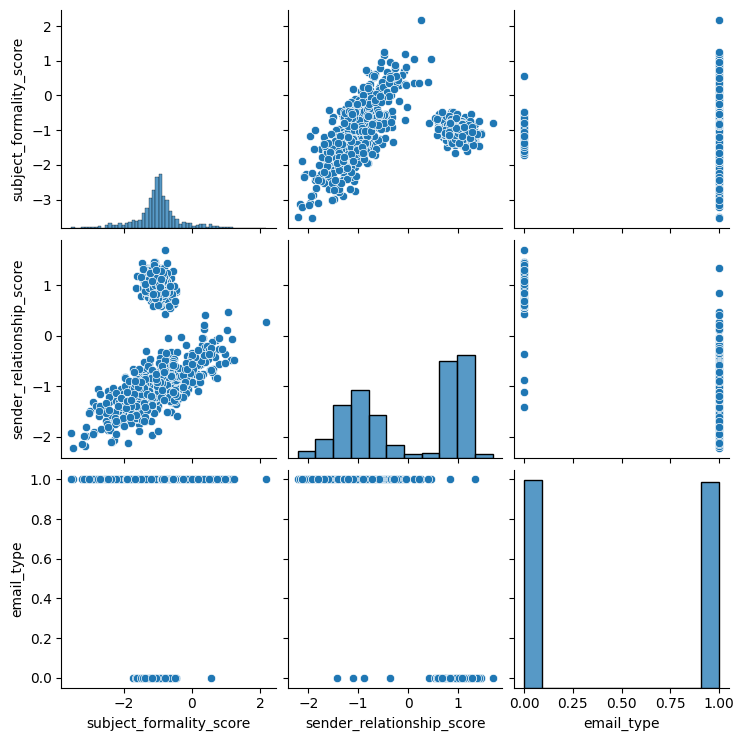

In [27]:
sns.pairplot(df)
plt.show()

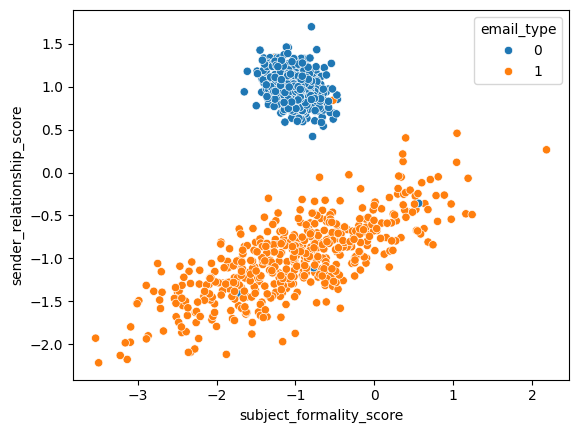

In [28]:
sns.scatterplot(data=df, x="subject_formality_score", y="sender_relationship_score", hue="email_type")
plt.show()

In [29]:
df["email_type"].value_counts()

,count
email_type,
0,502
1,498


In [30]:
X = df[["subject_formality_score", "sender_relationship_score"]].values
y = df["email_type"].values

In [31]:
from sklearn.model_selection import train_test_split

In [32]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [33]:
X_train

array([[-1.0117876 ,  1.23752419],
       [-0.17371594, -0.18965732],
       [-0.99900752,  0.96688407],
       ...,
       [-0.9629973 ,  1.26387822],
       [-1.20901347,  1.03434201],
       [-0.99495526,  1.09671733]])

In [34]:
len(X_train), len(X_test), len(y_train), len(y_test)

(800, 200, 800, 200)

In [35]:
X_train = torch.tensor(X_train, dtype=torch.float32) # model ile olan uyuşmazlığı düzeltmenin bir yol olarak.
X_test = torch.tensor(X_test, dtype=torch.float32)

y_train = torch.tensor(y_train, dtype=torch.float32).unsqueeze(1)
y_test = torch.tensor(y_test, dtype=torch.float32).unsqueeze(1)


In [36]:
print(X_train.shape, y_train.shape)
print(X_test.shape, y_test.shape)


torch.Size([800, 2]) torch.Size([800, 1])
torch.Size([200, 2]) torch.Size([200, 1])


In [38]:
y_train.ndim

2

In [39]:
X_train.ndim

2

In [40]:
from torch import nn

In [41]:
class ClassificationModel(nn.Module):
  def __init__(self):
    super().__init__()

    self.layer_1 = nn.Linear(in_features=2, out_features=5)
    self.layer_2 = nn.Linear(in_features=5, out_features=1)

  def forward(self, x: torch.tensor) -> torch.tensor:
    return self.layer_2(self.layer_1(x))

In [42]:
model = ClassificationModel()

In [53]:
torch.eq(torch.tensor([1,2,3]), torch.tensor([1,2,2])).sum()

tensor(2)

In [44]:
# loss function and optimizer

loss_fn = nn.BCEWithLogitsLoss()
optimizer = torch.optim.SGD(params=model.parameters(), lr=0.01)

In [54]:
def calculate_accuracy(y_test, y_pred):
  correct = torch.eq(y_test, y_pred).sum().item()
  accuracy = (correct/len(y_test)) * 100
  return accuracy

In [78]:
y_logits = model(X_test)[:] # bunlar logit değerler. Yani ham skorlar. Anlamsız.

In [79]:
y_logits

tensor([[-9.8490e-02],
        [ 1.2214e+00],
        [ 1.2712e-01],
        [ 7.6604e-01],
        [-8.1288e-02],
        [ 5.9208e-01],
        [ 7.3338e-01],
        [-8.1890e-02],
        [-6.3838e-02],
        [ 8.3082e-01],
        [ 1.8888e+00],
        [ 1.3584e+00],
        [-1.4460e-01],
        [-1.4667e-01],
        [-1.3258e-01],
        [ 1.7138e+00],
        [ 8.4612e-01],
        [ 1.6354e+00],
        [ 1.0701e+00],
        [ 8.1986e-01],
        [-1.5961e-02],
        [-3.6585e-02],
        [-1.6678e-01],
        [ 4.2943e-01],
        [ 5.5962e-01],
        [ 1.1392e+00],
        [-4.0892e-02],
        [ 7.4929e-01],
        [ 7.4893e-01],
        [ 3.4224e-01],
        [ 1.1931e+00],
        [ 8.4310e-01],
        [ 4.9709e-01],
        [ 4.2355e-02],
        [-1.3307e-01],
        [ 1.0266e+00],
        [-2.1423e-01],
        [ 9.3558e-01],
        [ 7.6909e-01],
        [-1.4624e-01],
        [ 9.2645e-02],
        [-5.2262e-02],
        [-6.2406e-02],
        [-7

In [80]:
y_pred_probs = torch.sigmoid(y_logits)

In [84]:
y_pred_probs[:5]

tensor([[0.4754],
        [0.7723],
        [0.5317],
        [0.6827],
        [0.4797]], grad_fn=<SliceBackward0>)

In [88]:
y_preds = torch.where(y_pred_probs<0.5, 0, 1)

In [89]:
calculate_accuracy(y_test, y_preds)

90.5